# Estimate TF activities for COSMOS with Python decoupler

**Question: which signed TF-target expression footprints support higher or lower activity in each cell line relative to this panel?**

This notebook translates the **RNA preprocessing and TF activity section** of [`scripts/prepare_cosmos_inputs.R`](../scripts/prepare_cosmos_inputs.R). It uses the same cleaned NCI60 RNA, the same CollecTRI snapshot, and the same univariate linear model (ULM). R is not required to run the notebook.

We will scale RNA, estimate activities, inspect real target footprints, compare with the archived R results, and export the RNA/TF matrices. Metabolomic preparation remains in the existing R workflow. See [README.md](README.md) for environment setup.

In [1]:
from pathlib import Path
import sys
import time
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import decoupler as dc
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "scripts" / "prepare_cosmos_inputs.R").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned COSMOS_basic repository.")
sys.path.insert(0, str(ROOT / "scripts"))
from tf_activity_decoupler import (
    load_rna, scale_rna, load_regulons, estimate_tf_activities, save_outputs,
)

RNA_PATH = ROOT / "data/RNA/RNA_log2_FPKM_cleaned_common.csv"
REGULON_PATH = ROOT / "GRN_comparison/data/collectri.tsv"
OUTPUT_DIR = ROOT / "TF_activity/results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CELL_LINE = "786-0"       # Also the default cell line in net_compr_MOON.R.
EXAMPLE_TF = "RELA"       # A named illustrative TF; change to another tested source.
MAX_MISSING = 20
MIN_TARGETS = 20
CHECK_R_REFERENCE = True  # Set False when changing the input, prior or preprocessing.

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def save_figure(fig, name):
    for extension in ("png", "pdf"):
        fig.savefig(OUTPUT_DIR / f"{name}.{extension}", dpi=160, bbox_inches="tight")

print("Python:", sys.version.split()[0], "| decoupler:", dc.__version__)
print("Interpreter:", sys.executable)

/Users/dugourd/Documents/COSMOS_basic/GRN_comparison/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.13 | decoupler: 2.2.0
Interpreter: /Users/dugourd/Documents/COSMOS_basic/GRN_comparison/.venv/bin/python


## 1. Start from the same RNA input as R

Rows are genes, columns are the **56 cell lines shared with metabolomics**, and entries are log₂(FPKM + 1). The earlier `scripts/RNA.R` has already replaced expression below 1 with missing values. We preserve those missing values.

This is the existing COSMOS input, distinct from the uncensored 60-line RNA matrix in the GRN-comparison practical. No raw-data reprocessing or new reference download is needed.

In [2]:
rna = load_rna(RNA_PATH)
assert CELL_LINE in rna.columns
print(f"Input: {rna.shape[0]:,} genes × {rna.shape[1]} cell lines")
print(f"Missing measurements: {rna.isna().to_numpy().mean():.1%}")
display(rna.iloc[:5, :6])

Input: 11,265 genes × 56 cell lines
Missing measurements: 18.9%


,786-0,A498,A549/ATCC,ACHN,BT-549,CAKI-1
gene,,,,,,
WASH7P,2.564,1.433,1.787,2.846,2.129,1.899
LOC729737,NaN,NaN,NaN,1.132,NaN,NaN
LOC100133331,NaN,NaN,NaN,4.720,NaN,NaN
LOC100288069,1.157,NaN,NaN,1.297,NaN,NaN
LINC01128,1.329,NaN,NaN,NaN,1.257,NaN


## 2. Match the R filtering and scaling

Keep genes with missing values in **at most 20 cell lines**, then scale each gene across its observed cell lines:

\[
z_{g,c}=\frac{x_{g,c}-\mathrm{mean}(x_g)}{\mathrm{sd}(x_g)},
\qquad \mathrm{sd}\text{ uses }n-1\text{ (sample SD).}
\]

A positive Z-score means that gene's RNA is above its own panel average in this cell line. It does not compare one gene's abundance with another's. Missing values remain missing; no imputation is performed. Constant genes would become unavailable, as in R.

The figure compares the original RNA and Z-scores for a few named genes. Changing the reference panel changes this baseline.

,value
n_input_genes,11265
n_removed_missing,2634
n_retained_genes,8631
n_zero_or_undefined_sd,0
n_cell_lines,56
max_missing,20
ddof,1
imputation,none


Observed genes in 786-0: 8,257


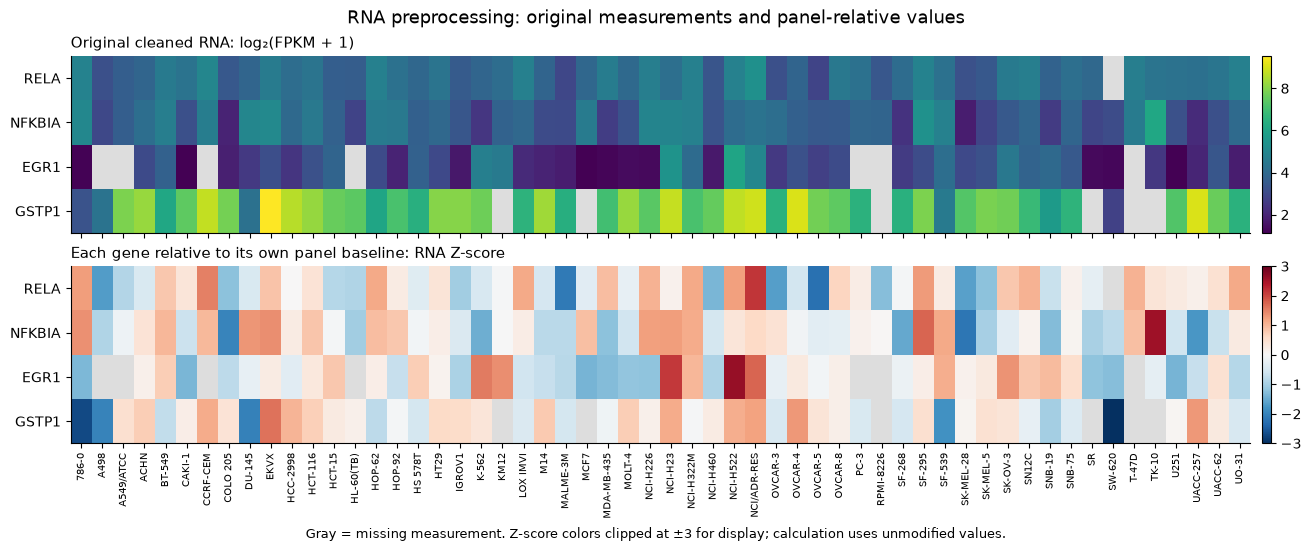

In [3]:
rna_scaled = scale_rna(rna, max_missing=MAX_MISSING)
display(pd.Series(rna_scaled.attrs["preprocessing"], name="value").to_frame())
print(f"Observed genes in {CELL_LINE}: {rna_scaled[CELL_LINE].notna().sum():,}")

shown_genes = [g for g in (EXAMPLE_TF, "NFKBIA", "EGR1", "GSTP1") if g in rna_scaled.index]
raw_view = rna.loc[shown_genes]
z_view = rna_scaled.loc[shown_genes]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.4), layout="constrained", sharex=True)
for ax, values, cmap, title, limit in (
    (axes[0], raw_view, "viridis", "Original cleaned RNA: log₂(FPKM + 1)", None),
    (axes[1], z_view, "RdBu_r", "Each gene relative to its own panel baseline: RNA Z-score", 3),
):
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("#dddddd")
    kwargs = {"vmin": -limit, "vmax": limit} if limit is not None else {}
    image = ax.imshow(values.to_numpy(), aspect="auto", cmap=cm, **kwargs)
    ax.set_yticks(range(len(shown_genes)), shown_genes)
    ax.set_title(title, loc="left", fontsize=11)
    fig.colorbar(image, ax=ax, pad=0.01, fraction=0.025)
axes[1].set_xticks(range(rna.shape[1]), rna.columns, rotation=90, fontsize=7)
fig.suptitle("RNA preprocessing: original measurements and panel-relative values", fontsize=13)
fig.supxlabel("Gray = missing measurement. Z-score colors clipped at ±3 for display; calculation uses unmodified values.", fontsize=9)
display(fig)
save_figure(fig, "rna_preprocessing")
plt.close(fig)

## 3. Reuse the same signed CollecTRI regulons

The bundled table is a text export of `support/collectri_regulon_R.RData`, not a query for a newer CollecTRI release. The original R `mor` column is preserved as `weight` for Python:

- **+1:** activating regulatory annotation.
- **−1:** repressing regulatory annotation.

A TF is scored through its targets; its own RNA need not be measured. Some source labels are complexes or cofactors. The [snapshot provenance](../GRN_comparison/data/provenance.json) records the source file and checksums.

In [4]:
regulons = load_regulons(REGULON_PATH)
print(f"Prior: {len(regulons):,} edges; {regulons.source.nunique():,} source regulons")
display(regulons.loc[regulons.source.eq(EXAMPLE_TF)].head(8))

Prior: 43,178 edges; 1,186 source regulons


,source,target,weight
30113,RELA,ABCA1,-1.0
30114,RELA,ABCB1,1.0
30115,RELA,ABCG2,1.0
30116,RELA,ABL1,1.0
30117,RELA,ADAM12,1.0
30118,RELA,ADAMTS5,1.0
30119,RELA,ADGRG3,1.0
30120,RELA,ADORA1,1.0


## 4. Estimate one cell line with ULM

For each TF, ULM fits the relationship between **signed regulatory weights** and observed gene Z-scores in one cell line. Genes outside that regulon have weight zero, so they contribute to the background. The fit includes an intercept.

The activity is the **t-statistic of the fitted slope**. Positive activity supports an activating-up/repressing-down pattern **relative to the zero-weight background**; negative activity supports the reverse. Each gene's RNA Z-score is itself relative to that gene's panel mean. This is an inferred footprint, not a measurement of TF protein or a log fold change.

To match R, drop missing genes **separately for each cell line** and require at least **20 available targets** (`minsize=20` in R, `tmin=20` in Python). Keep genuine zero Z-scores with `empty=False`: zero means a measured value at the gene's mean, not missing expression.

The following is the actual Python API call. In decoupler 2.x, the second returned table contains BH-adjusted p-values across the TFs tested in that cell line.

These p-values describe evidence under the gene-level model; they do not establish TF causality or replace biological replication.

In [5]:
observed = rna_scaled[CELL_LINE].dropna()
# Python expects observations in rows, genes in columns.
one_cell_scores, one_cell_padj = dc.mt.ulm(
    data=observed.to_frame().T,
    net=regulons,
    tmin=MIN_TARGETS,
    empty=False,
)
display(pd.DataFrame({
    "activity_t": one_cell_scores.loc[CELL_LINE],
    "BH_adjusted_p": one_cell_padj.loc[CELL_LINE],
}).sort_values("activity_t", ascending=False).head(10))

,activity_t,BH_adjusted_p
NFKB,6.096078,2.203507e-07
RELA,5.261135,1.423609e-05
RBPJ,5.105774,2.177991e-05
JUN,4.623608,1.856847e-04
NFKB2,4.297200,6.788193e-04
SMAD3,3.914883,2.948019e-03
REL,3.680141,6.501486e-03
WT1,3.563304,8.930868e-03
SPI1,3.503995,9.932010e-03
STAT3,3.425445,1.196559e-02


## 5. Repeat for all 56 cell lines

The helper below repeats that same call for each cell line. A common complete-gene intersection would discard valid measurements, and filling missing genes with zero would invent measurements, so neither is used.

The combined score matrix has a missing entry when a TF has fewer than 20 observed targets in that cell line. This is insufficient coverage, not activity zero. All tested scores are retained, matching the R script.

In [6]:
started = time.perf_counter()
result = estimate_tf_activities(rna_scaled, regulons, min_targets=MIN_TARGETS)
scores = result["scores"]
np.testing.assert_allclose(
    scores.loc[one_cell_scores.columns, CELL_LINE],
    one_cell_scores.loc[CELL_LINE], rtol=1e-10, atol=1e-10,
)
print(f"Estimated {scores.notna().sum().sum():,} activities in {time.perf_counter()-started:.1f} s")
print(f"Score matrix: {scores.shape[0]} TFs × {scores.shape[1]} cell lines")
display(result["cell_summary"].describe().round(1))

Estimated 10,548 activities in 2.1 s
Score matrix: 202 TFs × 56 cell lines


,n_genes,n_tfs_tested,zero_zscore_genes
count,56.0,56.0,56.0
mean,7983.7,188.4,0.1
std,497.8,10.2,0.2
min,6033.0,149.0,0.0
25%,7769.8,186.0,0.0
50%,8100.5,190.5,0.0
75%,8326.2,195.0,0.0
max,8511.0,200.0,1.0


### Compare activity patterns across the panel

The heatmap shows the **20 TFs with greatest activity-score SD across cell lines**, for readable exploration. Colors are the original ULM t-statistics, with a shared symmetric scale; TF rows are not standardized again. Gray entries indicate unavailable scores. This display selection does not filter the exported activities.

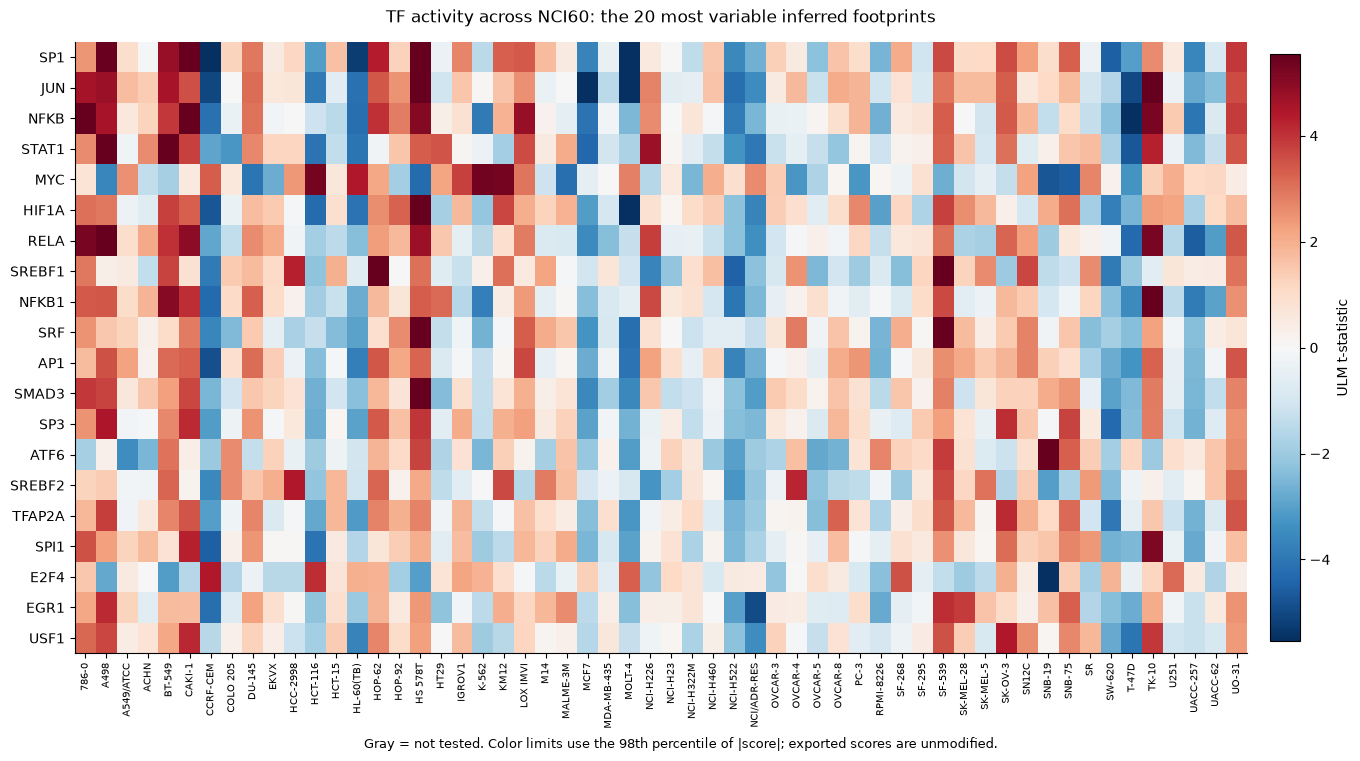

In [7]:
variable_tfs = scores.std(axis=1, skipna=True).sort_values(ascending=False).head(20).index
heatmap = scores.loc[variable_tfs]
limit = float(np.nanpercentile(np.abs(heatmap.to_numpy()), 98))
cm = plt.get_cmap("RdBu_r").copy()
cm.set_bad("#dddddd")
fig, ax = plt.subplots(figsize=(13.5, 7.5), layout="constrained")
image = ax.imshow(heatmap.to_numpy(), aspect="auto", cmap=cm, vmin=-limit, vmax=limit)
ax.set_yticks(range(len(variable_tfs)), variable_tfs)
ax.set_xticks(range(len(scores.columns)), scores.columns, rotation=90, fontsize=7)
ax.set_title("TF activity across NCI60: the 20 most variable inferred footprints", pad=14)
fig.colorbar(image, ax=ax, label="ULM t-statistic", fraction=0.025, pad=0.02)
fig.supxlabel("Gray = not tested. Color limits use the 98th percentile of |score|; exported scores are unmodified.", fontsize=9)
display(fig)
save_figure(fig, "tf_activity_heatmap")
plt.close(fig)

### Inspect activities in the COSMOS example cell line

The next plot shows eight positive and eight negative extremes in the selected cell line. The dashed lines reproduce the downstream R script's **heuristic `abs(score) > 2` seed filter**. This is not a BH/FDR threshold; keep it distinct from the adjusted p-values reported by decoupler.

TF source names can denote complexes, so a label such as `NFKB` should not be treated as the name of one measured transcript.

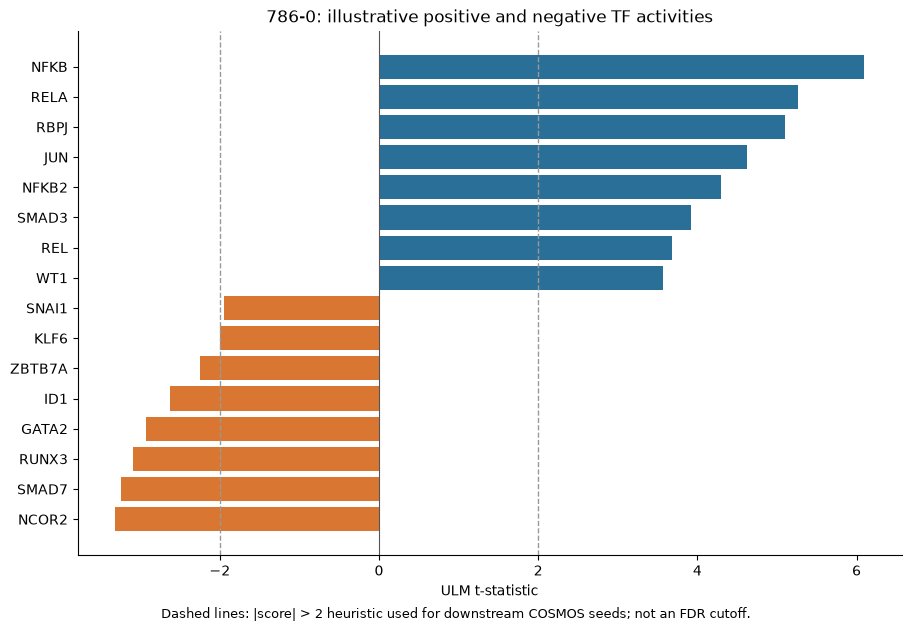

In [8]:
cell_scores = scores[CELL_LINE].dropna().sort_values()
extremes = pd.concat([cell_scores.head(8), cell_scores.tail(8)]).loc[lambda x: ~x.index.duplicated()]
fig, ax = plt.subplots(figsize=(9, 6.2), layout="constrained")
ax.barh(extremes.index, extremes.values,
        color=["#2A6F97" if value > 0 else "#D97732" for value in extremes])
ax.axvline(0, color="#555555", linewidth=0.8)
for cut in (-2, 2):
    ax.axvline(cut, color="#999999", linestyle="--", linewidth=1)
ax.set(title=f"{CELL_LINE}: illustrative positive and negative TF activities", xlabel="ULM t-statistic")
fig.supxlabel("Dashed lines: |score| > 2 heuristic used for downstream COSMOS seeds; not an FDR cutoff.", fontsize=9)
display(fig)
save_figure(fig, "tf_activity_selected_cell")
plt.close(fig)

## 6. Look at a real signed target footprint

We inspect **RELA in 786-0** by default; both names can be changed in the first code cell. The left panel shows the ULM inputs, including zero-weight background genes. The line is the full single-TF linear fit.

The right panel deliberately includes **five targets with highest and five with lowest signed Z-scores**, `sign(weight) × RNA Z-score`. Positive bars support the higher-activity pattern; negative bars support the lower-activity pattern. This illustrates coherent and contrary targets. These bars are not individual causal effects or an exact decomposition of the ULM t-statistic.

TF transcript abundance and TF activity are different quantities: one measures the TF's own RNA, while the other summarizes its targets' signed expression pattern.

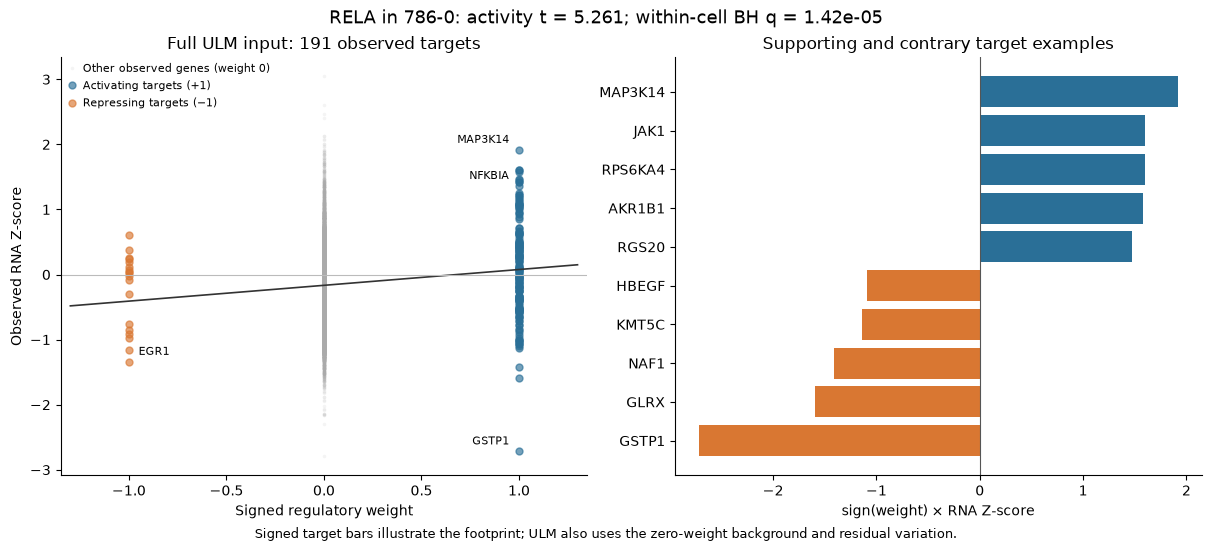

,quantity,value
0,TF's own log₂(FPKM + 1),4.843000
1,TF's own gene Z-score,1.248344
2,Target-derived ULM t-statistic,5.261135


In [9]:
if EXAMPLE_TF not in scores.index or pd.isna(scores.at[EXAMPLE_TF, CELL_LINE]):
    raise ValueError("Choose a TF with enough observed targets in the selected cell line.")
footprint = regulons.loc[regulons.source.eq(EXAMPLE_TF)].set_index("target").copy()
footprint["RNA_Z"] = rna_scaled[CELL_LINE].reindex(footprint.index)
footprint = footprint.dropna(subset=["RNA_Z"])
footprint["signed_Z"] = np.sign(footprint.weight) * footprint.RNA_Z
weights = footprint.weight.reindex(observed.index, fill_value=0.0)
coefficient, intercept = np.polyfit(weights.to_numpy(), observed.to_numpy(), 1)
activity = float(scores.at[EXAMPLE_TF, CELL_LINE])
adjusted_p = float(result["p_adjusted"].at[EXAMPLE_TF, CELL_LINE])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")
background = observed.loc[~observed.index.isin(footprint.index)]
axes[0].scatter(np.zeros(len(background)), background, color="#aaaaaa", s=7, alpha=0.12,
                linewidth=0, label="Other observed genes (weight 0)", rasterized=True)
for sign, color, label in ((1, "#2A6F97", "Activating targets (+1)"), (-1, "#D97732", "Repressing targets (−1)")):
    points = footprint.loc[np.sign(footprint.weight).eq(sign)]
    axes[0].scatter(points.weight, points.RNA_Z, s=25, color=color, alpha=0.65, label=label)
for gene in ("NFKBIA", "EGR1", "MAP3K14", "GSTP1"):
    if gene in footprint.index:
        row = footprint.loc[gene]
        axes[0].annotate(gene, (row.weight, row.RNA_Z),
                         xytext=(-7 if row.weight > 0 else 7, 5), textcoords="offset points",
                         ha="right" if row.weight > 0 else "left", fontsize=8)
line = np.array([-1.3, 1.3])
axes[0].plot(line, intercept + coefficient*line, color="#333333", linewidth=1.2)
axes[0].axhline(0, color="#bbbbbb", linewidth=0.8)
axes[0].set(xlim=(-1.35, 1.35), xlabel="Signed regulatory weight", ylabel="Observed RNA Z-score",
            title=f"Full ULM input: {len(footprint)} observed targets")
axes[0].legend(frameon=True, facecolor="white", edgecolor="none", framealpha=0.9, fontsize=8, loc="upper left")
selected = pd.concat([footprint.nsmallest(5, "signed_Z"), footprint.nlargest(5, "signed_Z")])
selected = selected.loc[~selected.index.duplicated()].sort_values("signed_Z")
axes[1].barh(selected.index, selected.signed_Z,
             color=np.where(selected.signed_Z >= 0, "#2A6F97", "#D97732"))
axes[1].axvline(0, color="#555555", linewidth=0.8)
axes[1].set(xlabel="sign(weight) × RNA Z-score", title="Supporting and contrary target examples")
fig.suptitle(f"{EXAMPLE_TF} in {CELL_LINE}: activity t = {activity:.3f}; within-cell BH q = {adjusted_p:.3g}", fontsize=13)
fig.supxlabel("Signed target bars illustrate the footprint; ULM also uses the zero-weight background and residual variation.", fontsize=9)
display(fig)
save_figure(fig, "signed_target_footprint")
plt.close(fig)
footprint.to_csv(OUTPUT_DIR / "selected_tf_target_footprint.csv")
if EXAMPLE_TF in rna_scaled.index:
    display(pd.DataFrame({"quantity": ["TF's own log₂(FPKM + 1)", "TF's own gene Z-score", "Target-derived ULM t-statistic"],
                          "value": [rna.at[EXAMPLE_TF, CELL_LINE], rna_scaled.at[EXAMPLE_TF, CELL_LINE], activity]}))

## 7. Check the Python translation against the archived R scores

The bundled reference below was exported from `data/cosmos/cosmos_inputs.RData`. It is used **only for validation**, after Python inference; it is never an input to ULM. Reading the text export requires no R installation. Its [provenance](data/r_reference_provenance.json) records the source archive and checksums.

This checks numerical reproduction of the original workflow, rather than biological correctness. For the default data and parameters, the tested TF–cell pairs and scores should agree up to numerical precision. If you change the RNA, regulons or filters, set `CHECK_R_REFERENCE=False`.

Matched 10,548 TF–cell scores; maximum absolute difference: 6.03e-13


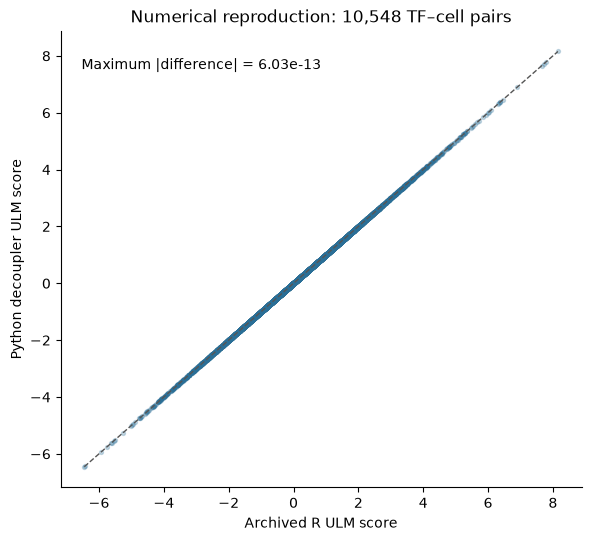

In [10]:
if CHECK_R_REFERENCE:
    reference = pd.read_csv(ROOT / "TF_activity/data/r_reference_tf_scores.tsv.gz", sep="\t")
    actual = (scores.rename_axis("source").reset_index()
              .melt(id_vars="source", var_name="cell_line", value_name="python_score")
              .dropna(subset=["python_score"]))
    reference = reference.rename(columns={"score": "R_score"})
    comparison = actual.merge(reference, on=["source", "cell_line"], how="outer", validate="one_to_one", indicator=True)
    assert comparison["_merge"].eq("both").all(), "Tested TF–cell pairs differ from R."
    comparison["difference"] = comparison.python_score - comparison.R_score
    np.testing.assert_allclose(comparison.python_score, comparison.R_score, rtol=1e-8, atol=1e-8)
    max_difference = float(comparison.difference.abs().max())
    print(f"Matched {len(comparison):,} TF–cell scores; maximum absolute difference: {max_difference:.2e}")
    comparison.to_csv(OUTPUT_DIR / "r_score_comparison.csv", index=False)
    fig, ax = plt.subplots(figsize=(5.8, 5.3), layout="constrained")
    ax.scatter(comparison.R_score, comparison.python_score, s=8, alpha=0.25, color="#2A6F97", rasterized=True)
    limits = [min(comparison.R_score.min(), comparison.python_score.min()),
              max(comparison.R_score.max(), comparison.python_score.max())]
    ax.plot(limits, limits, "--", color="#555555", linewidth=1)
    ax.set(xlabel="Archived R ULM score", ylabel="Python decoupler ULM score",
           title=f"Numerical reproduction: {len(comparison):,} TF–cell pairs")
    ax.text(0.04, 0.94, f"Maximum |difference| = {max_difference:.2e}", transform=ax.transAxes, va="top")
    display(fig)
    save_figure(fig, "r_python_agreement")
    plt.close(fig)
else:
    print("Reference comparison skipped for a modified workflow.")

## 8. Export activities and scaled RNA

Exports preserve **TFs/genes in rows and cell lines in columns**, with missing results written as `NA`. Activities remain unthresholded, as in `prepare_cosmos_inputs.R`. Raw ULM p-values are reconstructed from the t-statistics; native BH-adjusted p-values are provided separately for interpretation.

Files go to `TF_activity/results/`. The original RData and metabolomics inputs are untouched.

In [11]:
provenance = {
    "reference_workflow": "scripts/prepare_cosmos_inputs.R, RNA/TF section",
    "rna": {"path": str(RNA_PATH.relative_to(ROOT)), "sha256": hashlib.sha256(RNA_PATH.read_bytes()).hexdigest()},
    "regulons": {"path": str(REGULON_PATH.relative_to(ROOT)), "sha256": hashlib.sha256(REGULON_PATH.read_bytes()).hexdigest()},
}
paths = save_outputs(rna_scaled, result, OUTPUT_DIR, provenance=provenance)
display(pd.DataFrame({"output": paths.keys(), "file": [p.name for p in paths.values()]}))
print("Saved outputs:", OUTPUT_DIR)
print(f"{CELL_LINE}: {scores[CELL_LINE].notna().sum()} tested TFs; "
      f"{scores[CELL_LINE].abs().gt(2).sum()} pass the downstream |score| > 2 heuristic.")

,output,file
0,rna_scaled,rna_scaled.csv
1,tf_scores,tf_scores.csv
2,tf_pvalues,tf_pvalues.csv
3,tf_padj,tf_padj.csv
4,tf_target_counts,tf_target_counts.csv
5,cell_summary,cell_summary.csv
6,run_info,run_info.json


Saved outputs: /Users/dugourd/Documents/COSMOS_basic/TF_activity/results
786-0: 194 tested TFs; 50 pass the downstream |score| > 2 heuristic.


### Optional: use the Python exports in the existing R COSMOS workflow

From the repository root in R, read the exported matrices and extract named vectors. This replaces the TF/RNA vectors for a chosen cell line; keep using the existing metabolomic input. Save any reconstructed COSMOS input under a **new filename** if needed.

```r
tf_table <- read.csv("TF_activity/results/tf_scores.csv", row.names = 1, check.names = FALSE)
rna_table <- read.csv("TF_activity/results/rna_scaled.csv", row.names = 1, check.names = FALSE)
cell_line <- "786-0"
tf_input <- setNames(tf_table[[cell_line]], rownames(tf_table))
rna_input <- setNames(rna_table[[cell_line]], rownames(rna_table))
tf_input <- tf_input[is.finite(tf_input)]
rna_input <- rna_input[is.finite(rna_input)]
# Same explicit downstream seed filter as net_compr_MOON.R:
tf_input <- tf_input[abs(tf_input) > 2]
```

**Discussion:** why can a TF's own RNA abundance disagree with its activity estimate? Why must a missing activity remain distinct from zero? How would changing the reference cell-line panel change the inference?

Method references: [Python ULM](https://decoupler.scverse.org/en/latest/api/generated/decoupler.mt.ulm.html), [R ULM](https://saezlab.github.io/decoupleR/reference/run_ulm.html).